# Spotify Streaming Analytics: what really drives streams?

**Question:** which track attributes (popularity, genre, country, label, audio features, release timing, artist) actually move stream counts, and how concentrated is streaming?

**Data:** 85,000 tracks (2015-2025), 33 columns. `stream_count` is a per-track total, so there is **no time series of streams**; "trend by year" means *release year cohort*.

**Plan:** 1 data audit (is this data real?), 2 concentration, 3 popularity model, 4 machine learning with proper cross-validation, 5 segment tests with multiple-testing correction, 6 artists, 7 breakout over-performers, 8 conclusions.

In [1]:
import pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import r2_score, roc_auc_score, accuracy_score
from sklearn.inspection import permutation_importance
G1, G2, MINT, INK, GREY = '#1ED760', '#128C27', '#97F1A9', '#0E1712', '#5C6A63'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold'})
pd.options.display.float_format = '{:,.3f}'.format
rng = np.random.default_rng(42)

## 1. Data audit: is this data real?

In [2]:
d = pd.read_csv('../data/spotify_tracks.csv.gz', parse_dates=['release_date']); s = d.stream_count; N = len(d)
print(f'{N:,} tracks x {d.shape[1]} columns | missing values: {int(d.isna().sum().sum())} | duplicate track_id: {int(d.track_id.duplicated().sum())}')
rows = []
for c in ['genre', 'country', 'label', 'key_name', 'mode_name', 'release_day_of_week']:
    o = d[c].value_counts(); rows.append((f'{c}: counts vs uniform (chi-square)', stats.chisquare(o.values).pvalue, o.min() / N, o.max() / N))
for c in ['danceability', 'energy', 'instrumentalness', 'tempo', 'loudness', 'duration_ms']:
    u = (d[c] - d[c].min()) / (d[c].max() - d[c].min()); ks = stats.kstest(u, 'uniform'); rows.append((f'{c}: KS vs uniform (D={ks.statistic:.3f})', ks.pvalue, np.nan, np.nan))
pd.DataFrame(rows, columns=['test', 'p-value', 'min share', 'max share']).round(3)

85,000 tracks x 33 columns | missing values: 0 | duplicate track_id: 0


,test,p-value,min share,max share
0,genre: counts vs uniform (chi-square),0.351,0.081,0.085
1,country: counts vs uniform (chi-square),0.232,0.098,0.102
2,label: counts vs uniform (chi-square),0.639,0.124,0.127
3,key_name: counts vs uniform (chi-square),0.681,0.082,0.085
4,mode_name: counts vs uniform (chi-square),0.934,0.500,0.500
5,release_day_of_week: counts vs uniform (chi-sq...,0.137,0.141,0.146
6,danceability: KS vs uniform (D=0.008),0.000,NaN,NaN
7,energy: KS vs uniform (D=0.007),0.001,NaN,NaN
8,instrumentalness: KS vs uniform (D=0.003),0.312,NaN,NaN
9,tempo: KS vs uniform (D=0.002),0.949,NaN,NaN


In [3]:
facts = {'all stream counts multiples of 1,000': bool((s % 1000 == 0).all()), 'tracks exactly at the 20,000,000 cap': int((s == 20_000_000).sum()), 'share at the 1,000 floor': round(float((s == 1000).mean()), 4),
         'mean loudness (dB)': round(d.loudness.mean(), 1), 'loudness range': (d.loudness.min(), d.loudness.max()), 'Major / Minor': (int((d['mode'] == 1).sum()), int((d['mode'] == 0).sum())),
         'upbeat_score == (danceability+energy)/2': bool(np.allclose(d.upbeat_score, (d.danceability + d.energy) / 2)), 'log_stream_count == log1p(streams)': bool(np.allclose(np.log1p(s), d.log_stream_count)),
         'unique track names': d.track_name.nunique(), 'unique artist names': d.artist_name.nunique(), 'tracks at popularity 100': int((d.popularity == 100).sum())}
Xa = d[['danceability', 'energy', 'loudness', 'tempo', 'instrumentalness', 'duration_minutes', 'popularity', 'explicit']].values; yg = d.genre.astype('category').cat.codes.values
pg = cross_val_predict(HistGradientBoostingClassifier(max_iter=80, random_state=1), Xa, yg, cv=StratifiedKFold(3, shuffle=True, random_state=1))
facts['genre predicted from audio features: accuracy (chance = 8.33%)'] = round(accuracy_score(yg, pg), 4); pd.Series(facts, name='finding')

all stream counts multiples of 1,000                                        True
tracks exactly at the 20,000,000 cap                                         458
share at the 1,000 floor                                                   0.384
mean loudness (dB)                                                       -28.000
loudness range                                                     (-55.0, -1.0)
Major / Minor                                                     (42512, 42488)
upbeat_score == (danceability+energy)/2                                     True
log_stream_count == log1p(streams)                                          True
unique track names                                                         68952
unique artist names                                                        62391
tracks at popularity 100                                                     397
genre predicted from audio features: accuracy (chance = 8.33%)             0.083
Name: finding, dtype: object

**Verdict: the file behaves like synthetic data.** Categorical counts are indistinguishable from uniform random draws, audio features are independent uniforms (genre cannot be recovered from them), streams are rounded to 1,000 and clipped at 20 million, and loudness averages -28 dB (real catalogues sit near -8 dB). The analysis below is therefore a rigorous test of *what this file contains*, not a statement about the real streaming market. Its real value is the method, which transfers unchanged to production data.

## 2. Concentration: who gets the streams?

total 18,220,148,000 | mean 214,355 | median 2,000 | p90 59,000 | p99 5,751,090 | Gini 0.969
{'top 0.1': 0.0933, 'top 1': 0.7346, 'top 5': 0.9474, 'top 10': 0.975, 'top 20': 0.9889, 'top 50': 0.9971}
hit threshold (99th percentile) = 5,751,090; hit tracks = 850


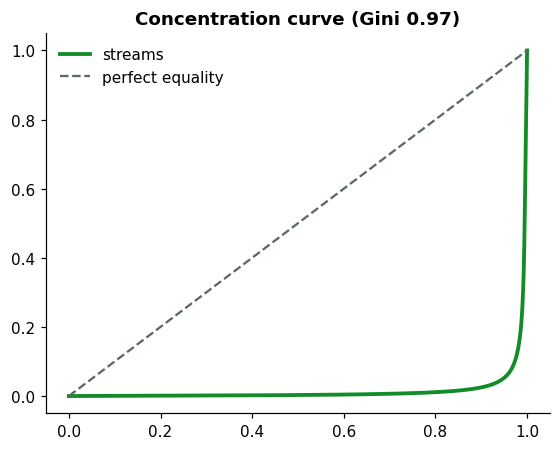

In [4]:
srt = np.sort(s.values)[::-1]; cs = srt.cumsum() / srt.sum(); x = np.sort(s.values)
gini = (2 * np.arange(1, N + 1) - N - 1).dot(x) / (N * x.sum())
print(f'total {s.sum():,} | mean {s.mean():,.0f} | median {s.median():,.0f} | p90 {s.quantile(.9):,.0f} | p99 {s.quantile(.99):,.0f} | Gini {gini:.3f}')
print({f'top {p}': round(float(cs[int(round(N * p / 100)) - 1]), 4) for p in (0.1, 1, 5, 10, 20, 50)})
HIT = s.quantile(.99); d['hit'] = (s >= HIT).astype(int); print(f'hit threshold (99th percentile) = {HIT:,.0f}; hit tracks = {d.hit.sum()}')
lor = np.sort(s.values).cumsum() / s.sum(); p = np.arange(1, N + 1) / N
fig, ax = plt.subplots(figsize=(5.2, 4.2)); ax.plot(p, lor, color=G2, lw=2.5, label='streams'); ax.plot([0, 1], [0, 1], '--', color=GREY, label='perfect equality'); ax.set_title('Concentration curve (Gini %.2f)' % gini); ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Insight.** Streaming is a winner-take-most system. The top 1% of tracks (850) earn **73.5%** of all streams, the top 10% earn 97.5%, while the median track earns **2,000** and 38% of tracks sit at the 1,000 floor. Averages are meaningless here; hit rate is the right metric.

## 3. Popularity is the engine

In [5]:
sl = stats.linregress(d.popularity, np.log(s)); print(f'log-linear fit: R2 = {sl.rvalue**2:.3f}; each +10 popularity points multiplies streams by x{np.exp(sl.slope*10):.2f}; Spearman rho = {stats.spearmanr(d.popularity, s)[0]:.3f}')
b = pd.cut(d.popularity, [-1, 20, 35, 50, 65, 80, 100]); g = d.groupby(b, observed=True).agg(tracks=('stream_count', 'size'), mean=('stream_count', 'mean'), median=('stream_count', 'median'), total=('stream_count', 'sum'), hit_rate=('hit', 'mean'))
g['% of tracks'] = g.tracks / N * 100; g['% of streams'] = g.total / s.sum() * 100; g.drop(columns='total').round(3)

log-linear fit: R2 = 0.546; each +10 popularity points multiplies streams by x2.59; Spearman rho = 0.639


,tracks,mean,median,hit_rate,% of tracks,% of streams
popularity,,,,,,
"(-1, 20]",1128,"1,292.553","1,000.000",0.000,1.327,0.008
"(20, 35]",14829,"1,905.658","1,000.000",0.000,17.446,0.155
"(35, 50]",35952,"4,499.110","2,000.000",0.000,42.296,0.888
"(50, 65]",23063,"27,452.283","6,000.000",0.000,27.133,3.475
"(65, 80]",7291,"347,003.017","56,000.000",0.008,8.578,13.886
"(80, 100]",2737,"5,431,329.193","1,406,000.000",0.290,3.220,81.589


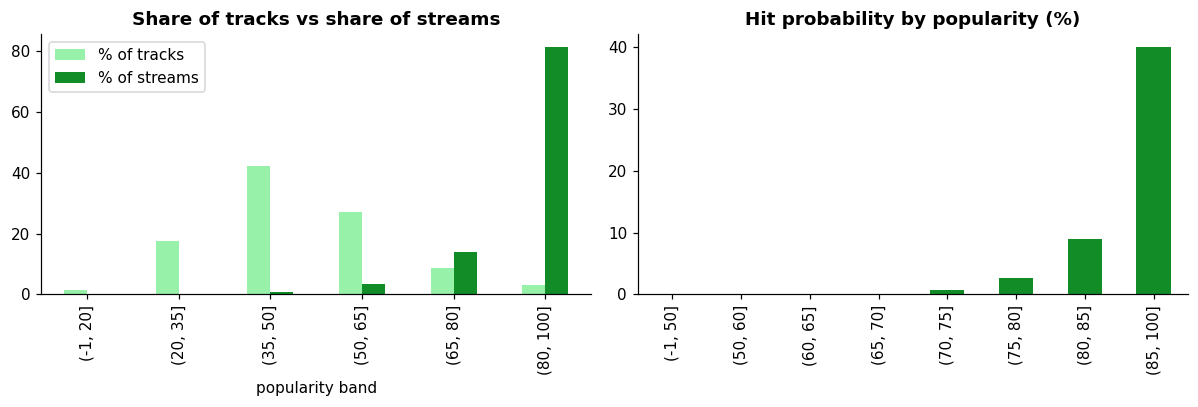

In [6]:
hr = d.groupby(pd.cut(d.popularity, [-1, 50, 60, 65, 70, 75, 80, 85, 100]), observed=True).hit.mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); g[['% of tracks', '% of streams']].plot.bar(ax=ax[0], color=[MINT, G2]); ax[0].set_title('Share of tracks vs share of streams'); ax[0].set_xlabel('popularity band')
(hr * 100).plot.bar(ax=ax[1], color=G2); ax[1].set_title('Hit probability by popularity (%)'); ax[1].set_xlabel(''); plt.tight_layout(); plt.show()

**Insight.** Tracks with popularity above 80 are **3.2% of the catalogue but 81.6% of streams**. The chance of reaching the top 1% is 0.0% below popularity 66, 9.0% at 81-85 and **40.1% above 85**. A hit is almost impossible without popularity momentum.

## 4. Machine learning with honest validation (5-fold CV)

In [7]:
feat = ['popularity', 'danceability', 'energy', 'loudness', 'tempo', 'instrumentalness', 'duration_minutes', 'explicit', 'release_year', 'release_month', 'artist_track_count', 'key', 'mode']
dm = pd.get_dummies(d[['genre', 'country', 'label']].astype('category')).astype(int); XA = pd.concat([d[feat], dm], axis=1); XB = XA.drop(columns=['popularity']); y = np.log1p(s.values)
kf = KFold(5, shuffle=True, random_state=7); res = {}
for nm, X in [('Popularity only', d[['popularity']]), ('Everything EXCEPT popularity', XB), ('Everything', XA)]:
    pr = cross_val_predict(HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, random_state=1), X, y, cv=kf); res[nm] = round(r2_score(y, pr), 4)
print('cross-validated R2 on log streams:', res)
hf = StratifiedKFold(5, shuffle=True, random_state=7); auc = {}
for nm, X in [('Popularity only', d[['popularity']]), ('Everything EXCEPT popularity', XB), ('Everything', XA)]:
    pp = cross_val_predict(HistGradientBoostingClassifier(max_iter=120, random_state=1), X, d.hit, cv=hf, method='predict_proba')[:, 1]; auc[nm] = round(roc_auc_score(d.hit, pp), 3)
print('ROC AUC for "is a hit":', auc)

cross-validated R2 on log streams: {'Popularity only': 0.6343, 'Everything EXCEPT popularity': -0.0007, 'Everything': 0.6331}


ROC AUC for "is a hit": {'Popularity only': 0.992, 'Everything EXCEPT popularity': 0.491, 'Everything': 0.989}


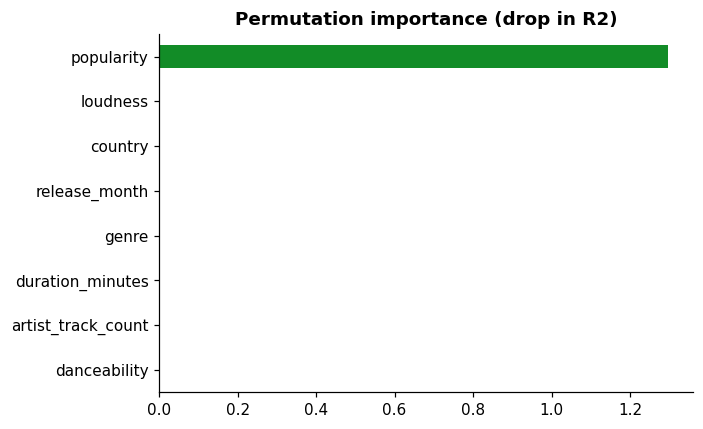

In [8]:
mdl = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.08, random_state=1).fit(XA.iloc[:60000], y[:60000])
pi = permutation_importance(mdl, XA.iloc[60000:72000], y[60000:72000], n_repeats=4, random_state=3, scoring='r2'); imp = pd.Series(pi.importances_mean, index=XA.columns)
grp = {c: imp[c] for c in feat}; [grp.__setitem__(k, imp[[c for c in XA.columns if c.startswith(k + '_')]].sum()) for k in ('genre', 'country', 'label')]
imp_s = pd.Series(grp).sort_values(ascending=False); fig, ax = plt.subplots(figsize=(6.5, 4)); imp_s.head(8)[::-1].plot.barh(ax=ax, color=[GREY] * 7 + [G2]); ax.set_title('Permutation importance (drop in R2)'); plt.tight_layout(); plt.show()

**Insight.** Popularity alone explains **63.4%** of the variance in log streams and separates hits with an AUC of **0.99** (0.992 cross-validated). Everything else *combined* explains **0.0%** (R2 = -0.001, AUC 0.49, a coin flip). Permutation importance agrees: popularity 1.30, every other feature about 0.00.

## 5. Do genre, country, label or timing matter? (with multiple-testing correction)

In [9]:
seg = []
for c in ['genre', 'country', 'label', 'key_name', 'mode_name', 'release_day_of_week', 'release_quarter', 'release_year', 'explicit', 'is_weekend_release', 'loudness_category']:
    gr = [v.values for _, v in d.groupby(c).log_stream_count]; kw = stats.kruskal(*gr); m = d.groupby(c).stream_count.mean(); seg.append((c, kw.pvalue, m.min(), m.max()))
sg = pd.DataFrame(seg, columns=['variable', 'raw p', 'min mean streams', 'max mean streams']); o = sg['raw p'].argsort().values; holm = np.empty(len(sg)); run = 0
for rank, i in enumerate(o): run = max(run, min(1, sg['raw p'][i] * (len(sg) - rank))); holm[i] = run
sg['Holm p'] = holm; sg['verdict'] = np.where(sg['Holm p'] < .05, 'significant', 'not significant'); sg.round(3)

,variable,raw p,min mean streams,max mean streams,Holm p,verdict
0,genre,0.011,"179,534.894","266,307.542",0.124,not significant
1,country,0.202,"191,027.451","234,555.814",1.000,not significant
2,label,0.778,"196,843.361","231,833.838",1.000,not significant
3,key_name,0.964,"201,501.347","228,600.567",1.000,not significant
4,mode_name,0.555,"212,634.127","216,076.210",1.000,not significant
5,release_day_of_week,0.248,"202,031.030","231,084.211",1.000,not significant
6,release_quarter,0.319,"201,351.558","239,791.541",1.000,not significant
7,release_year,0.579,"181,105.003","239,311.522",1.000,not significant
8,explicit,0.454,"210,545.083","215,315.009",1.000,not significant
9,is_weekend_release,0.191,"209,970.612","225,439.518",1.000,not significant


In [10]:
codes = d.genre.astype('category').cat.codes.values; sv = s.values.astype(float); spread = pd.Series(sv).groupby(codes).mean().agg(lambda z: z.max() - z.min())
sp = [pd.Series(sv).groupby(rng.permutation(codes)).mean().pipe(lambda z: z.max() - z.min()) for _ in range(1500)]
print(f'genre: observed spread of mean streams {spread:,.0f} vs permutation median {np.median(sp):,.0f}; permutation p = {(np.array(sp) >= spread).mean():.3f}')
yr = d.release_year.values; cv = lambda z: z.std() / z.mean(); obs = cv(pd.Series(sv).groupby(yr).sum()); pm = [cv(pd.Series(sv).groupby(rng.permutation(yr)).sum()) for _ in range(1000)]
print(f'release-year totals: CV {obs:.3f} vs permutation median {np.median(pm):.3f}; p = {(np.array(pm) >= obs).mean():.3f}')

genre: observed spread of mean streams 86,773 vs permutation median 64,001; permutation p = 0.084


release-year totals: CV 0.100 vs permutation median 0.088; p = 0.303


**Insight.** After Holm correction **no segment variable is significant** (smallest adjusted p = 0.12, genre). Genre differences in total streams are inside the range random shuffling produces (permutation p is about 0.08, Monte Carlo), and the year-to-year swing in total streams is chance (permutation p is about 0.3). The apparent "best genre" (Hip-Hop 10.5% of streams) is noise created by a few capped mega-tracks.

## 6. Artists

In [11]:
a = d.groupby('artist_name').agg(tracks=('track_id', 'size'), streams=('stream_count', 'sum'), best=('stream_count', 'max'))
print(f'{len(a):,} artist names | top 10 artists hold {a.streams.nlargest(10).sum()/s.sum():.2%} of streams | top 1% of artists hold {a.streams.nlargest(int(len(a)*.01)).sum()/s.sum():.1%}')
mt = a[a.tracks >= 3]; print(f'artists with 3+ tracks: best track delivers {(mt.best / mt.streams).mean():.0%} of their streams on average | most tracks under one name: {a.tracks.max()}')
a.nlargest(5, 'streams')

62,391 artist names | top 10 artists hold 1.49% of streams | top 1% of artists hold 64.3%
artists with 3+ tracks: best track delivers 70% of their streams on average | most tracks under one name: 44


,tracks,streams,best
artist_name,,,
Anthony Walker,5,40008000,20000000
Peter Hall,3,34132000,20000000
Rebecca Brown,9,27892000,19396000
Kimberly Smith,12,26801000,20000000
Jason Owens,4,25351000,18197000


**Insight.** Artist-level success is mostly one or two hit songs (a single track delivers about 70% of a multi-track artist's streams). `artist_name` is not a unique ID (one name covers 44 tracks), so artist rankings are indicative only.

## 7. Breakout over-performers

In [12]:
ml_ = d.groupby('popularity').log_stream_count.mean().rolling(5, center=True, min_periods=1).mean(); d['expected'] = np.exp(d.popularity.map(ml_)) - 1; d['lift'] = s / d.expected
print(f"breakout score (streams / expected at that popularity): 99th percentile x{d.lift.quantile(.99):.0f}, max x{d.lift.max():.0f}")
d.nlargest(5, 'lift')[['track_name', 'artist_name', 'popularity', 'stream_count', 'lift']].round(1)

breakout score (streams / expected at that popularity): 99th percentile x27, max x618


,track_name,artist_name,popularity,stream_count,lift
64417,Baby without fall,Alexis Taylor,68,20000000,618.400
50309,Sea,Crystal Hawkins,69,20000000,532.000
82287,It maybe,Jose Holland,58,3611000,478.800
15788,Carry,Noah Reynolds,58,3255000,431.600
27720,Sort stuff,Ivan Boyd,53,1558000,365.900


## 8. Conclusions and recommendations

1. **Popularity is the only lever.** 3.2% of tracks (popularity > 80) earn 81.6% of streams; hit probability reaches 40% above 85. Concentrate marketing on tracks with popularity momentum.
2. **Sound does not sell.** Audio features, key, mode, explicit and release timing show |rho| < 0.006 with streams; models without popularity explain 0%. Do not pay for audio or genre optimisation.
3. **Genre, country and label are equals** (no significant effect after correction). Diversify; do not chase short-term share gaps.
4. **Manage a long tail.** Gini 0.97; judge portfolios by hit rate, not mean streams (mean 214K vs median 2K).
5. **Study breakout tracks** that beat their popularity-implied expectation by 27x or more.
6. **Validate on production data.** The file shows fingerprints of synthetic generation, so re-run this pipeline on real streaming data before acting.